Running on: cpu

Training data shape: (20631, 26)
Testing data shape: (13096, 26)

First five rows:
   unit  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  sensor_3  \
0     1      1    -0.0007    -0.0004      100.0    518.67    641.82   1589.70   
1     1      2     0.0019    -0.0003      100.0    518.67    642.15   1591.82   
2     1      3    -0.0043     0.0003      100.0    518.67    642.35   1587.99   
3     1      4     0.0007     0.0000      100.0    518.67    642.35   1582.79   
4     1      5    -0.0019    -0.0002      100.0    518.67    642.37   1582.85   

   sensor_4  sensor_5  ...  sensor_12  sensor_13  sensor_14  sensor_15  \
0   1400.60     14.62  ...     521.66    2388.02    8138.62     8.4195   
1   1403.14     14.62  ...     522.28    2388.07    8131.49     8.4318   
2   1404.20     14.62  ...     522.42    2388.03    8133.23     8.4178   
3   1401.87     14.62  ...     522.86    2388.08    8133.83     8.3682   
4   1406.22     14.62  ...     522.19    23

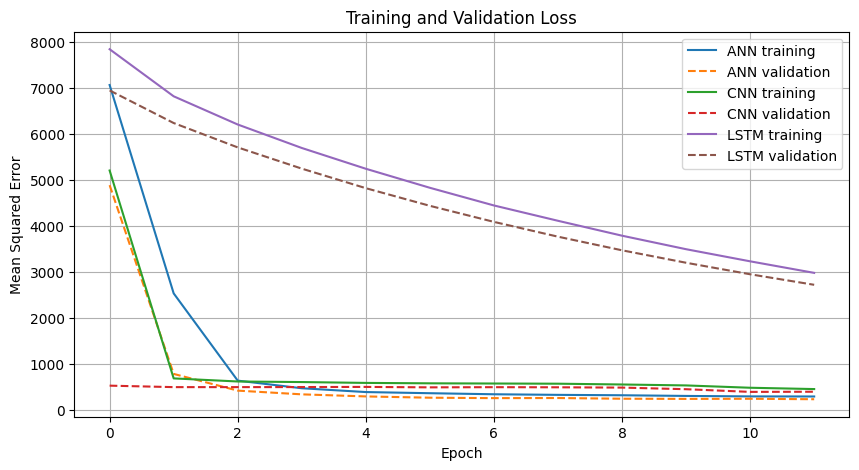

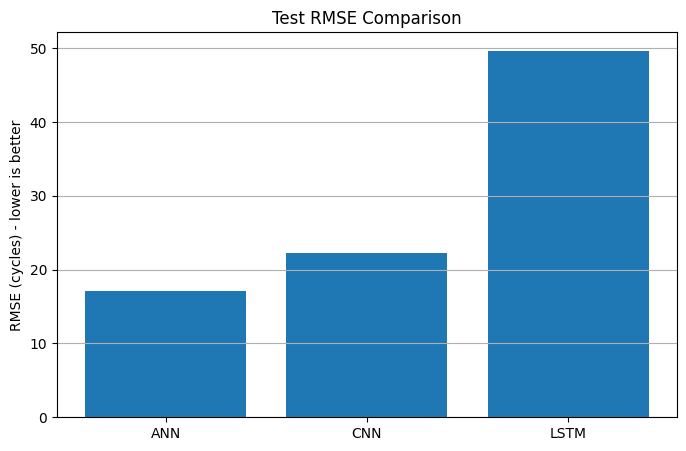

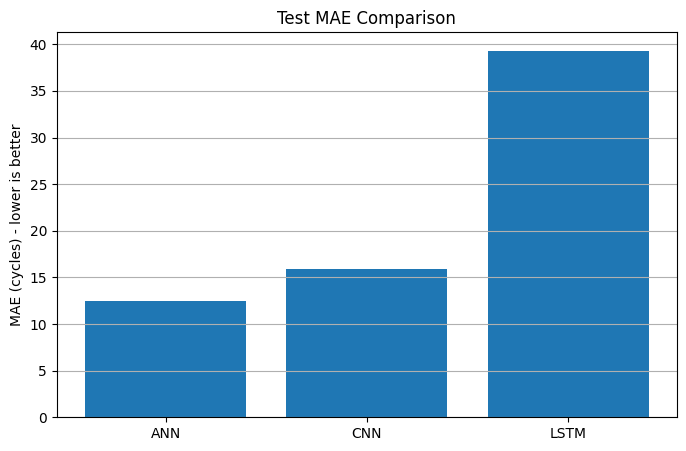

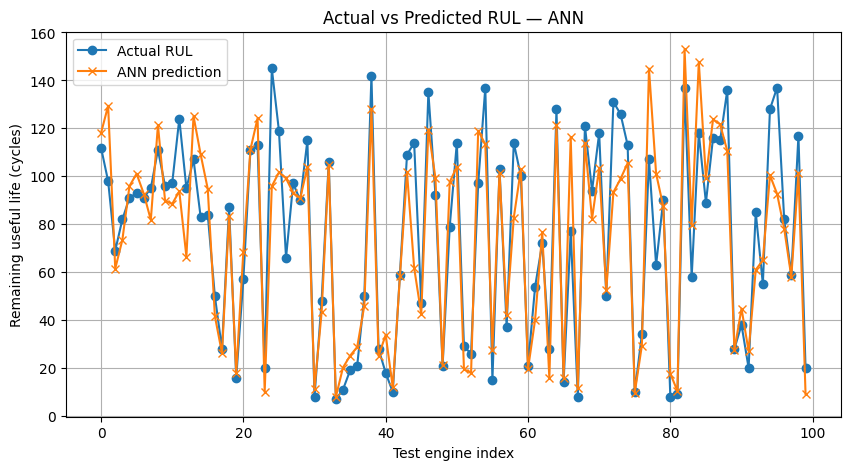


Example predictions from the best model:
 Engine  Actual RUL  Predicted RUL  Absolute Error
      1       112.0          118.0             6.0
      2        98.0          129.4            31.4
      3        69.0           61.5             7.5
      4        82.0           73.4             8.6
      5        91.0           95.9             4.9
      6        93.0          101.1             8.1
      7        91.0           92.8             1.8
      8        95.0           81.8            13.2
      9       111.0          121.3            10.3
     10        96.0           89.9             6.1

Saved files:
best_ann_model.pth
cmapss_scaler.pkl
model_comparison.csv

Loading a pretrained Hugging Face Transformer...


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Sample text: The engine sensor readings show increasing vibration and the predicted remaining useful life is low.
Transformer output: [{'label': 'NEGATIVE', 'score': 0.9997225403785706}]

PROJECT COMPLETE


In [1]:

# ============================================================
# HACK-O-WEEK: AIRCRAFT ENGINE PREDICTIVE MAINTENANCE
# Dataset: NASA C-MAPSS FD001
# Framework: PyTorch
# Models: ANN, 1D CNN, LSTM
# ============================================================

import os
import copy
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

# 1. REPRODUCIBILITY AND DEVICE
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running on:", device)

# 2. DOWNLOAD THE REAL DATASET
BASE_URL = (
    "https://raw.githubusercontent.com/"
    "subhodeepmoitra/NASA---CMAPSSData/main/"
)

FILES = {
    "train": "train_FD001.txt",
    "test": "test_FD001.txt",
    "rul": "RUL_FD001.txt"
}

def download_file(filename):
    url = BASE_URL + filename
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    return response.text

try:
    train_text = download_file(FILES["train"])
    test_text = download_file(FILES["test"])
    rul_text = download_file(FILES["rul"])

    from io import StringIO

    train_df = pd.read_csv(
        StringIO(train_text), sep=r"\s+", header=None
    )
    test_df = pd.read_csv(
        StringIO(test_text), sep=r"\s+", header=None
    )
    test_rul = pd.read_csv(
        StringIO(rul_text), sep=r"\s+", header=None
    ).iloc[:, 0].to_numpy()

except Exception as e:
    raise RuntimeError(
        "Dataset download failed. Check your internet connection "
        "or download the three FD001 files from "
        "https://github.com/subhodeepmoitra/NASA---CMAPSSData"
    ) from e

columns = (
    ["unit", "cycle", "setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train_df.columns = columns
test_df.columns = columns

print("\nTraining data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)
print("\nFirst five rows:")
print(train_df.head())

# 3. CREATE THE REMAINING USEFUL LIFE (RUL) TARGET
# RUL = final cycle of engine - current cycle
# Cap at 125 cycles to make learning more stable.

MAX_RUL = 125
WINDOW = 30

train_df["RUL"] = (
    train_df.groupby("unit")["cycle"].transform("max")
    - train_df["cycle"]
).clip(upper=MAX_RUL)

feature_cols = columns[2:]

# Remove constant sensor columns using training data only.
variances = train_df[feature_cols].var()
feature_cols = variances[variances > 1e-8].index.tolist()

print("\nNumber of useful input features:", len(feature_cols))
print("Sequence window:", WINDOW, "cycles")

# 4. SPLIT BY ENGINE, NOT BY INDIVIDUAL ROW
# This prevents readings from the same engine appearing in
# both training and validation sets.

units = train_df["unit"].unique()
train_units, val_units = train_test_split(
    units, test_size=0.20, random_state=SEED
)

train_part = train_df[train_df["unit"].isin(train_units)].copy()
val_part = train_df[train_df["unit"].isin(val_units)].copy()

# Fit the scaler only on training-engine readings.
scaler = StandardScaler()
scaler.fit(train_part[feature_cols])

for part in [train_part, val_part, test_df]:
    part[feature_cols] = scaler.transform(part[feature_cols])

# 5. CREATE SEQUENCES OF SENSOR READINGS

def make_training_sequences(df, window):
    X, y = [], []

    for _, engine in df.groupby("unit", sort=True):
        engine = engine.sort_values("cycle")
        values = engine[feature_cols].to_numpy(dtype=np.float32)
        targets = engine["RUL"].to_numpy(dtype=np.float32)

        # Each sequence predicts RUL at its last cycle.
        for end in range(window, len(engine) + 1):
            X.append(values[end-window:end])
            y.append(targets[end-1])

    return np.asarray(X, dtype=np.float32), np.asarray(
        y, dtype=np.float32
    )

X_train, y_train = make_training_sequences(train_part, WINDOW)
X_val, y_val = make_training_sequences(val_part, WINDOW)

# The test files end before failure. The supplied RUL file gives
# the true remaining cycles at each test engine's last cycle.
X_test, y_test = [], []

for unit in sorted(test_df["unit"].unique()):
    engine = test_df[test_df["unit"] == unit].sort_values("cycle")
    values = engine[feature_cols].to_numpy(dtype=np.float32)

    if len(values) < WINDOW:
        pad = np.repeat(values[:1], WINDOW-len(values), axis=0)
        values = np.concatenate([pad, values], axis=0)

    X_test.append(values[-WINDOW:])

    # RUL at last observed cycle = supplied final RUL.
    # Use the original unit order in the official RUL file.
    X_test_unit_order = unit - 1
    y_test.append(test_rul[X_test_unit_order])

X_test = np.asarray(X_test, dtype=np.float32)
y_test = np.asarray(y_test, dtype=np.float32)

print("\nSequence shapes:")
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

# 6. CONVERT ARRAYS INTO PYTORCH TENSORS

def make_loader(X, y, shuffle=False):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32)
    )
    return DataLoader(
        dataset,
        batch_size=256,
        shuffle=shuffle
    )

train_loader = make_loader(X_train, y_train, True)
val_loader = make_loader(X_val, y_val)
test_loader = make_loader(X_test, y_test)

# 7. DEFINE THREE NEURAL NETWORKS

class ANN(nn.Module):
    # Baseline fully connected network.
    def __init__(self, window, features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(window * features, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


class CNN1D(nn.Module):
    # Learns local patterns across consecutive cycles.
    def __init__(self, features):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(features, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.25),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x = x.transpose(1, 2)
        return self.head(self.conv(x)).squeeze(1)


class LSTMModel(nn.Module):
    # Learns how sensor conditions change with time.
    def __init__(self, features):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=features,
            hidden_size=64,
            num_layers=1,
            batch_first=True
        )
        self.dropout = nn.Dropout(0.25)
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        sequence_output, _ = self.lstm(x)
        last_output = sequence_output[:, -1, :]
        return self.fc(self.dropout(last_output)).squeeze(1)


# 8. TRAINING LOOP WITH AUTOGRAD, ADAM AND EARLY STOPPING

def train_model(model, name, epochs=12, patience=3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_function = nn.MSELoss()

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    wait = 0
    history = {"train": [], "val": []}

    for epoch in range(epochs):
        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            predictions = model(xb)
            loss = loss_function(predictions, yb)
            loss.backward()       # Autograd: calculate gradients
            optimizer.step()      # Update model parameters

            train_losses.append(loss.item())

        model.eval()
        val_losses = []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                predictions = model(xb)
                loss = loss_function(predictions, yb)
                val_losses.append(loss.item())

        train_loss = np.mean(train_losses)
        val_loss = np.mean(val_losses)
        history["train"].append(train_loss)
        history["val"].append(val_loss)

        print(
            f"{name:5s} | Epoch {epoch+1:02d}/{epochs} "
            f"| Train MSE: {train_loss:.2f} "
            f"| Validation MSE: {val_loss:.2f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping activated.")
                break

    model.load_state_dict(best_weights)
    return model, history


# 9. TRAIN ALL THREE MODELS

models = {
    "ANN": ANN(WINDOW, len(feature_cols)),
    "CNN": CNN1D(len(feature_cols)),
    "LSTM": LSTMModel(len(feature_cols))
}

trained_models = {}
histories = {}

for name, model in models.items():
    print("\nTraining", name)
    trained_models[name], histories[name] = train_model(
        model, name
    )

# 10. EVALUATE ON HELD-OUT TEST ENGINES

results = []
predictions = {}

for name, model in trained_models.items():
    model.eval()
    all_predictions = []

    with torch.no_grad():
        for xb, _ in test_loader:
            xb = xb.to(device)
            all_predictions.extend(
                model(xb).cpu().numpy().tolist()
            )

    pred = np.asarray(all_predictions)
    pred = np.maximum(pred, 0)
    predictions[name] = pred

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    results.append({
        "Model": name,
        "MAE (cycles)": round(mae, 2),
        "RMSE (cycles)": round(rmse, 2),
        "R2": round(r2, 3)
    })

results_df = pd.DataFrame(results).sort_values("RMSE (cycles)")

print("\n========== TEST RESULTS ==========")
print(results_df.to_string(index=False))
print("\nLower MAE and RMSE indicate better predictions.")
print("R2 closer to 1 indicates a better fit.")

# 11. GRAPH: TRAINING VS VALIDATION LOSS

plt.figure(figsize=(10, 5))
for name, history in histories.items():
    plt.plot(history["train"], label=f"{name} training")
    plt.plot(history["val"], linestyle="--", label=f"{name} validation")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

# 12. GRAPH: MODEL COMPARISON

plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["RMSE (cycles)"])
plt.title("Test RMSE Comparison")
plt.ylabel("RMSE (cycles) - lower is better")
plt.grid(axis="y")
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["MAE (cycles)"])
plt.title("Test MAE Comparison")
plt.ylabel("MAE (cycles) - lower is better")
plt.grid(axis="y")
plt.show()

# 13. GRAPH: ACTUAL VS PREDICTED RUL

best_name = results_df.iloc[0]["Model"]
best_predictions = predictions[best_name]

plt.figure(figsize=(10, 5))
plt.plot(y_test, label="Actual RUL", marker="o")
plt.plot(best_predictions, label=f"{best_name} prediction", marker="x")
plt.title(f"Actual vs Predicted RUL — {best_name}")
plt.xlabel("Test engine index")
plt.ylabel("Remaining useful life (cycles)")
plt.legend()
plt.grid(True)
plt.show()

# 14. SHOW EXAMPLE PREDICTIONS

example_df = pd.DataFrame({
    "Engine": np.arange(1, len(y_test) + 1),
    "Actual RUL": y_test,
    "Predicted RUL": np.round(best_predictions, 1),
    "Absolute Error": np.round(
        np.abs(y_test - best_predictions), 1
    )
})

print("\nExample predictions from the best model:")
print(example_df.head(10).to_string(index=False))

# 15. SAVE THE BEST MODEL AND SCALER

torch.save(
    trained_models[best_name].state_dict(),
    f"best_{best_name.lower()}_model.pth"
)

import joblib
joblib.dump(scaler, "cmapss_scaler.pkl")

results_df.to_csv("model_comparison.csv", index=False)

print("\nSaved files:")
print(f"best_{best_name.lower()}_model.pth")
print("cmapss_scaler.pkl")
print("model_comparison.csv")

# 16. HUGGING FACE TRANSFORMER DEMONSTRATION
# This is a separate NLP demo, NOT part of the RUL predictor.
# It uses a pretrained Transformer to classify text sentiment.

try:
    from transformers import pipeline

    print("\nLoading a pretrained Hugging Face Transformer...")
    text_classifier = pipeline(
        "sentiment-analysis",
        model="distilbert/distilbert-base-uncased-finetuned-sst-2-english"
    )

    sample_text = (
        "The engine sensor readings show increasing vibration "
        "and the predicted remaining useful life is low."
    )

    print("Sample text:", sample_text)
    print("Transformer output:", text_classifier(sample_text))

except Exception as e:
    print("\nTransformer demonstration skipped:", str(e))
    print("Run this section separately if model download fails.")

print("\nPROJECT COMPLETE")
